# Wandou HealthBench Analysis

This notebook analyzes results from the Wandou HealthBench eval for Qwen model.

## Imports and constants

In [67]:
import json
import pandas as pd
from typing import Literal
import matplotlib.pyplot as plt
import numpy as np
import textwrap
from collections import Counter, defaultdict
import matplotlib.dates as mdates
import seaborn as sns
import os

sns.set_theme(
    style="dark",
    palette="muted",
    font="serif",
    rc={
        "figure.dpi": 120,
        "axes.titleweight": "normal",
        "axes.labelweight": "normal",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "legend.frameon": False,
        "figure.autolayout": True,
        "legend.fontsize": "small",
        "legend.title_fontsize": "medium",
        "xtick.labelsize": "small",
        "ytick.labelsize": "small",
    }
)

## Configuration

In [68]:
# Path to the evaluation results file
fp_main_eval = './healthbench_wandou_healthbench_20260121_110832.json'

# what directory should results be saved to?
results_dir = './'

## Helper Functions

In [69]:
def _strip_prefix(tag: str) -> str:
    if ":" in tag:
        tag = tag.split(":", 1)[1]
    return tag.replace("_", " ").replace("-", " ").capitalize()

## Load Main Eval Data

In [70]:
# Load main eval results
with open(fp_main_eval, 'r') as f:
    main_eval_data = json.load(f)

# Extract the individual results
individual_results = main_eval_data.get('individual_results', [])

# Also store the overall metrics
overall_score = main_eval_data.get('score', 0)
overall_metrics = main_eval_data.get('metrics', {})

In [71]:
print(f"Number of individual results: {len(individual_results)}")
print(f"Overall score: {overall_score}")
if individual_results:
    print(f"Keys in first result: {list(individual_results[0].keys())}")

Number of individual results: 3
Overall score: 0.6499482203570457
Keys in first result: ['question', 'answer', 'score', 'metrics', 'evaluation_details']


## Extract Metrics for Visualization

In [72]:
# Process the results to create metrics for visualization
def extract_qwen_metrics(individual_results, overall_data):
    # Initialize metrics structure
    qwen_metrics = {}
    
    # Track scores by axis and theme
    axis_scores = defaultdict(list)
    theme_scores = defaultdict(list)
    cluster_scores = defaultdict(list)
    
    # Process individual results
    for result in individual_results:
        if 'metrics' in result:
            metrics = result['metrics']
            
            # Extract axis, theme, and cluster scores from metrics
            for key, value in metrics.items():
                if key.startswith('axis:'):
                    axis = key.replace('axis:', '')
                    axis_scores[axis].append(value)
                elif key.startswith('theme:'):
                    theme = key.replace('theme:', '')
                    theme_scores[theme].append(value)
                elif key.startswith('cluster:'):
                    cluster = key.replace('cluster:', '')
                    cluster_scores[cluster].append(value)
    
    # Calculate averages for each axis
    for axis, scores in axis_scores.items():
        if scores:
            avg_score = sum(scores) / len(scores)
            qwen_metrics[f'axis:{axis}'] = avg_score
            qwen_metrics[f'axis:{axis}:bootstrap_std'] = 0.0  # Placeholder
            qwen_metrics[f'axis:{axis}:n_samples'] = len(scores)
    
    # Calculate averages for each theme
    for theme, scores in theme_scores.items():
        if scores:
            avg_score = sum(scores) / len(scores)
            qwen_metrics[f'theme:{theme}'] = avg_score
            qwen_metrics[f'theme:{theme}:bootstrap_std'] = 0.0  # Placeholder
            qwen_metrics[f'theme:{theme}:n_samples'] = len(scores)
    
    # Calculate averages for each cluster
    for cluster, scores in cluster_scores.items():
        if scores:
            avg_score = sum(scores) / len(scores)
            qwen_metrics[f'cluster:{cluster}'] = avg_score
            qwen_metrics[f'cluster:{cluster}:bootstrap_std'] = 0.0  # Placeholder
            qwen_metrics[f'cluster:{cluster}:n_samples'] = len(scores)
    
    # Add overall score from the main state
    overall_score = overall_data.get('score', 0)
    qwen_metrics['overall_score'] = overall_score
    qwen_metrics['overall_score:bootstrap_std'] = 0.0  # Placeholder
    qwen_metrics['overall_score:n_samples'] = len(individual_results) if individual_results else 1
    
    # Add overall metrics if available
    overall_metrics = overall_data.get('metrics', {})
    for key, value in overall_metrics.items():
        if key not in qwen_metrics:  # Don't overwrite calculated values
            qwen_metrics[key] = value
    
    return {"Qwen": qwen_metrics}

# Extract metrics for Qwen model
qwen_results = extract_qwen_metrics(individual_results, main_eval_data)
print(f"Available metrics in qwen_results: {list(qwen_results['Qwen'].keys()) if 'Qwen' in qwen_results else []}")

Available metrics in qwen_results: ['axis:accuracy', 'axis:accuracy:bootstrap_std', 'axis:accuracy:n_samples', 'axis:completeness', 'axis:completeness:bootstrap_std', 'axis:completeness:n_samples', 'axis:context_awareness', 'axis:context_awareness:bootstrap_std', 'axis:context_awareness:n_samples', 'axis:communication_quality', 'axis:communication_quality:bootstrap_std', 'axis:communication_quality:n_samples', 'axis:instruction_following', 'axis:instruction_following:bootstrap_std', 'axis:instruction_following:n_samples', 'theme:global_health', 'theme:global_health:bootstrap_std', 'theme:global_health:n_samples', 'theme:context_seeking', 'theme:context_seeking:bootstrap_std', 'theme:context_seeking:n_samples', 'cluster:global_health_context-matters-is-clear_aligned_accurate', 'cluster:global_health_context-matters-is-clear_aligned_accurate:bootstrap_std', 'cluster:global_health_context-matters-is-clear_aligned_accurate:n_samples', 'cluster:global_health_context-matters-is-clear_languag

## Create Visualizations

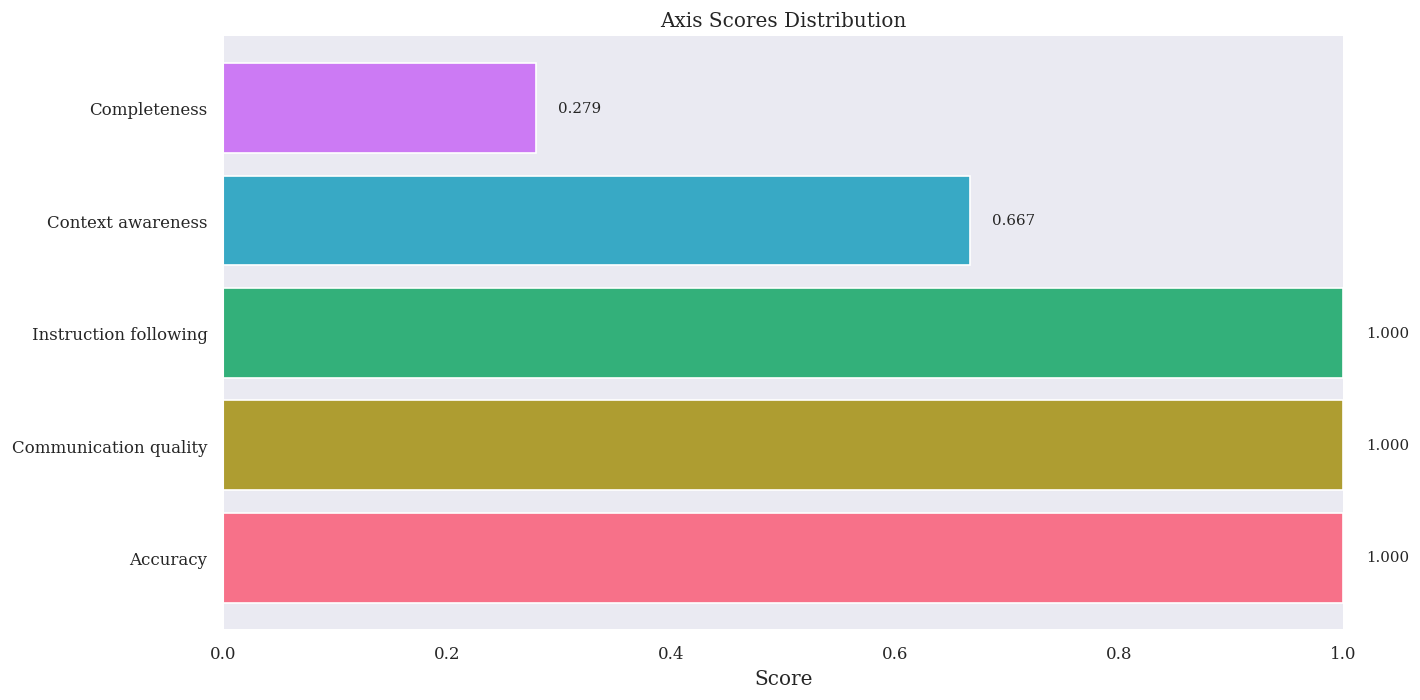

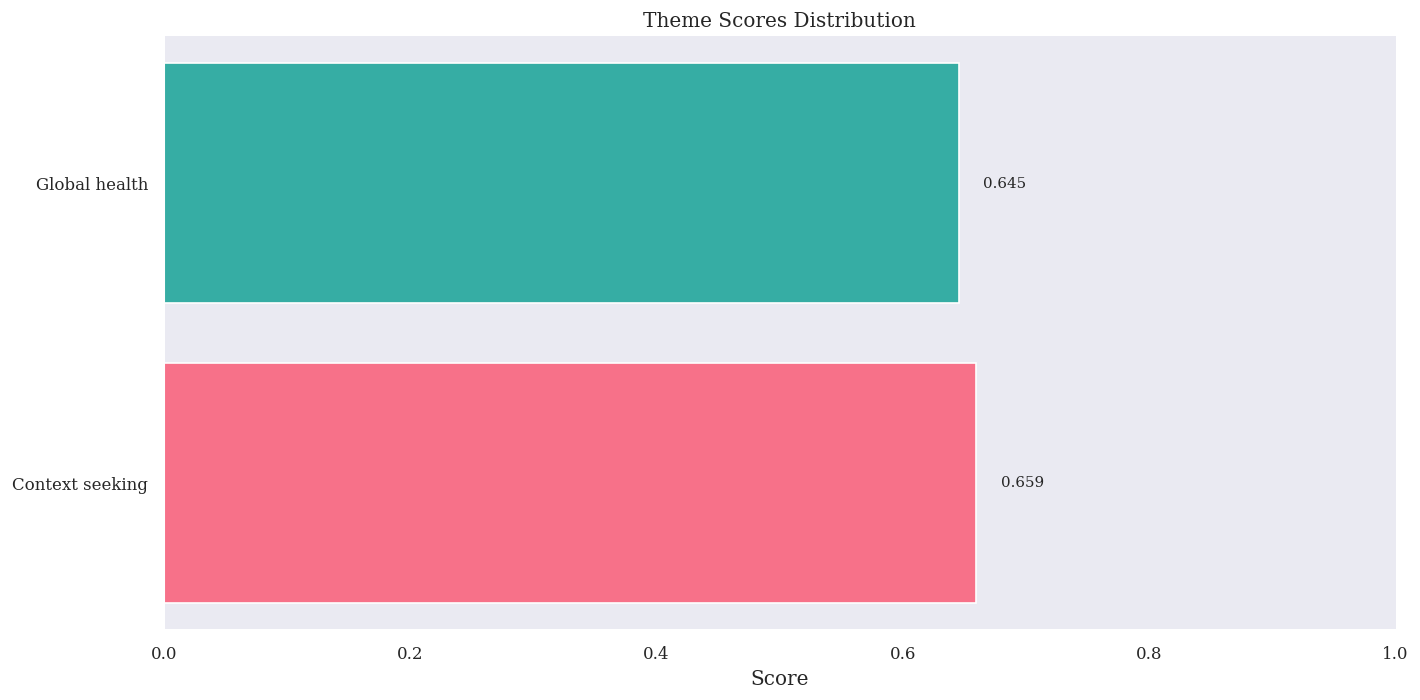

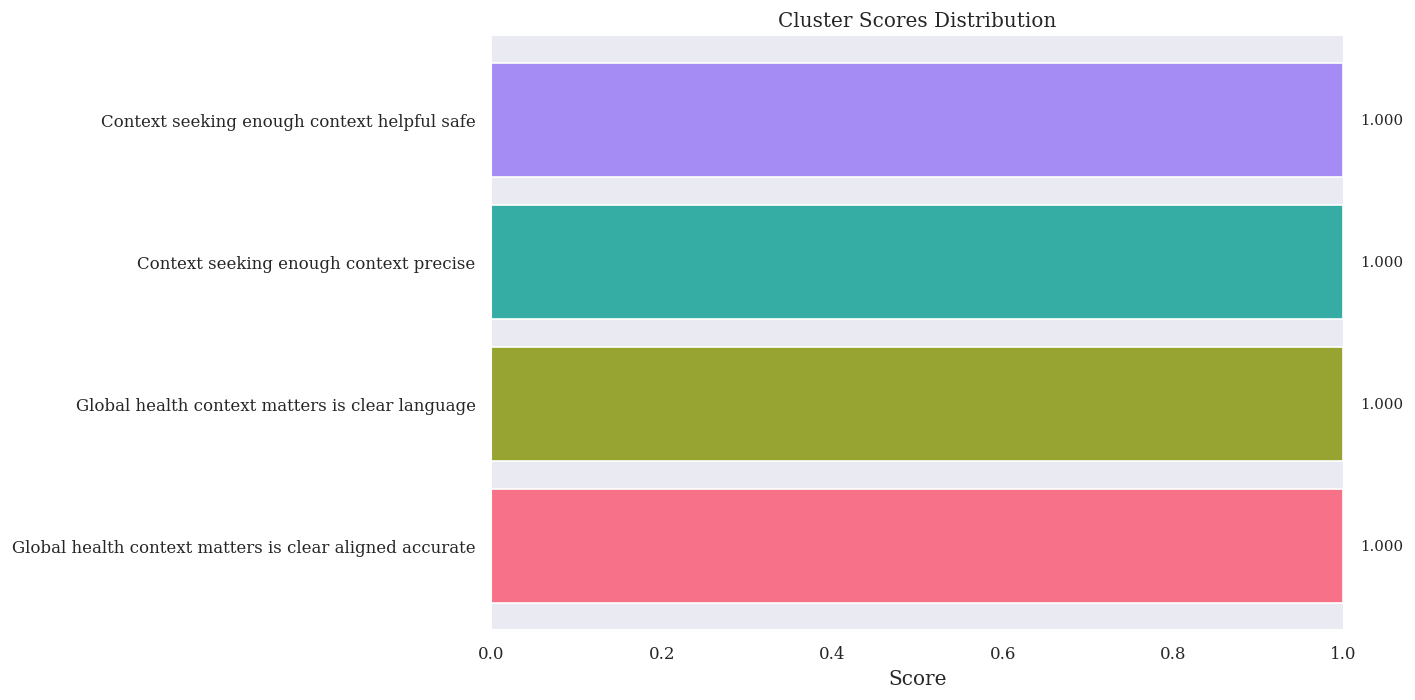

In [73]:
# Create visualizations for axes
def plot_metric_distribution(results_dict, metric_type: Literal["axis", "theme", "cluster"]):
    fig, ax = plt.subplots(figsize=(12, max(6, len([k for k in results_dict['Qwen'].keys() if k.startswith(metric_type + ':') and not k.endswith(':bootstrap_std') and not k.endswith(':n_samples')]) * 0.35)))
    
    # Get metrics of the specified type
    metric_keys = [k for k in results_dict['Qwen'].keys() 
                   if k.startswith(metric_type + ':') 
                   and not k.endswith(':bootstrap_std') 
                   and not k.endswith(':n_samples')]
    
    if not metric_keys:
        print(f"No data available for {metric_type}")
        return
    
    # Sort metrics by score
    metric_keys.sort(key=lambda x: results_dict['Qwen'][x], reverse=True)
    
    # Extract labels and values
    labels = [_strip_prefix(k) for k in metric_keys]
    values = [results_dict['Qwen'][k] for k in metric_keys]
    
    # Create horizontal bar plot
    bars = ax.barh(range(len(labels)), values, color=sns.color_palette("husl", len(labels)))
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)
    ax.set_xlabel('Score')
    ax.set_title(f'{metric_type.capitalize()} Scores Distribution')
    ax.set_xlim(0, 1)
    
    # Add value labels on bars
    for i, v in enumerate(values):
        ax.text(v + 0.02, i, f'{v:.3f}', va='center', fontsize=9)
    
    plt.tight_layout()
    plt.show()

# Plot axis scores
plot_metric_distribution(qwen_results, "axis")

# Plot theme scores
plot_metric_distribution(qwen_results, "theme")

# Plot cluster scores
plot_metric_distribution(qwen_results, "cluster")

## Save Results to CSV

In [74]:
# Save metrics to CSV
def save_results_to_csv(results_dict, results_dir: str = './'):
    os.makedirs(results_dir, exist_ok=True)
    
    # Define metric types to save
    metric_types = ["axis", "theme", "cluster"]
    
    for metric_type in metric_types:
        # Get metrics of the specified type
        metric_keys = [k for k in results_dict['Qwen'].keys() 
                       if k.startswith(metric_type + ':') 
                       and not k.endswith(':bootstrap_std') 
                       and not k.endswith(':n_samples')]
        
        if not metric_keys:
            continue
        
        # Prepare data for DataFrame
        labels = [_strip_prefix(k) for k in metric_keys]
        values = [results_dict['Qwen'][k] for k in metric_keys]
        
        # Create DataFrame
        df = pd.DataFrame({
            'Metric': labels,
            'Score': values
        })
        
        # Add model column
        df.insert(0, 'Model', 'Qwen')
        
        # Save to CSV
        csv_filename = f'{results_dir}/{metric_type}_scores.csv'
        df.to_csv(csv_filename, index=False)
        print(f'Saved {metric_type} scores to {csv_filename}')
        print(df.head())  # Display first few rows
        print()  # Empty line for spacing

# Save all results to CSV
save_results_to_csv(qwen_results, results_dir)

Saved axis scores to .//axis_scores.csv
  Model                 Metric     Score
0  Qwen               Accuracy  1.000000
1  Qwen           Completeness  0.278813
2  Qwen      Context awareness  0.666667
3  Qwen  Communication quality  1.000000
4  Qwen  Instruction following  1.000000

Saved theme scores to .//theme_scores.csv
  Model           Metric     Score
0  Qwen    Global health  0.645252
1  Qwen  Context seeking  0.659341

Saved cluster scores to .//cluster_scores.csv
  Model                                             Metric  Score
0  Qwen  Global health context matters is clear aligned...    1.0
1  Qwen    Global health context matters is clear language    1.0
2  Qwen             Context seeking enough context precise    1.0
3  Qwen        Context seeking enough context helpful safe    1.0

